# Chapitre 8 - Cours 1 : pannes partielles et réseaux non fiables

Sur une seule machine, un programme correct se comporte de façon **déterministe** : il
marche ou il plante. Dès que plusieurs machines coopèrent à travers un réseau, une partie
du système peut être en panne pendant que le reste fonctionne, et l'on ne sait même pas
toujours si une opération a réussi. Ce notebook pose ce constat et l'examine du point de
vue du réseau. Il couvre les sections *Faults and Partial Failures* et *Unreliable
Networks* (*Network Faults in Practice*, *Detecting Faults*) du chapitre 8.

**Plan.**

1. Pannes partielles : la machine seule contre le système distribué.
2. Ce que l'émetteur d'une requête ne peut pas savoir.
3. Les pannes réseau en pratique.
4. Détecter les fautes : les rares signaux explicites, et le délai d'expiration.

In [1]:
import socket
import struct
import threading
import time

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import numpy as np
import pandas as pd

from ddia import distsys as ds
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, set_style, subtitle)
from ddia.requirements import plain_log_axis
from ddia.sim import Network, Node
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 4)
rng = np.random.default_rng(0)

## 1. Pannes partielles : la machine seule contre le système distribué (section *Faults and Partial Failures*)

Un ordinateur est conçu pour présenter une **abstraction idéale** : une instruction fait
toujours la même chose, une donnée écrite en mémoire y reste. Quand le matériel défaille
(mémoire corrompue, connecteur desserré), le concepteur préfère que la machine **s'arrête
complètement** (panique du noyau, écran bleu) plutôt que de rendre un résultat faux :
un résultat faux est bien plus difficile à gérer qu'un arrêt. La machine est donc
entièrement fonctionnelle ou entièrement en panne, rarement entre les deux (le cours 4
du chapitre 1 a montré que ce n'est pas tout à fait vrai, mais assez
rarement pour qu'on l'ignore souvent).

Un système distribué n'a pas ce luxe. Certaines de ses parties peuvent être cassées
**de façon imprévisible** pendant que d'autres marchent : c'est une **panne partielle**
(partial failure). Et elle est **non déterministe** : la même opération sur plusieurs
nœuds réussit parfois, échoue parfois, et parfois on ne sait pas si elle a réussi.

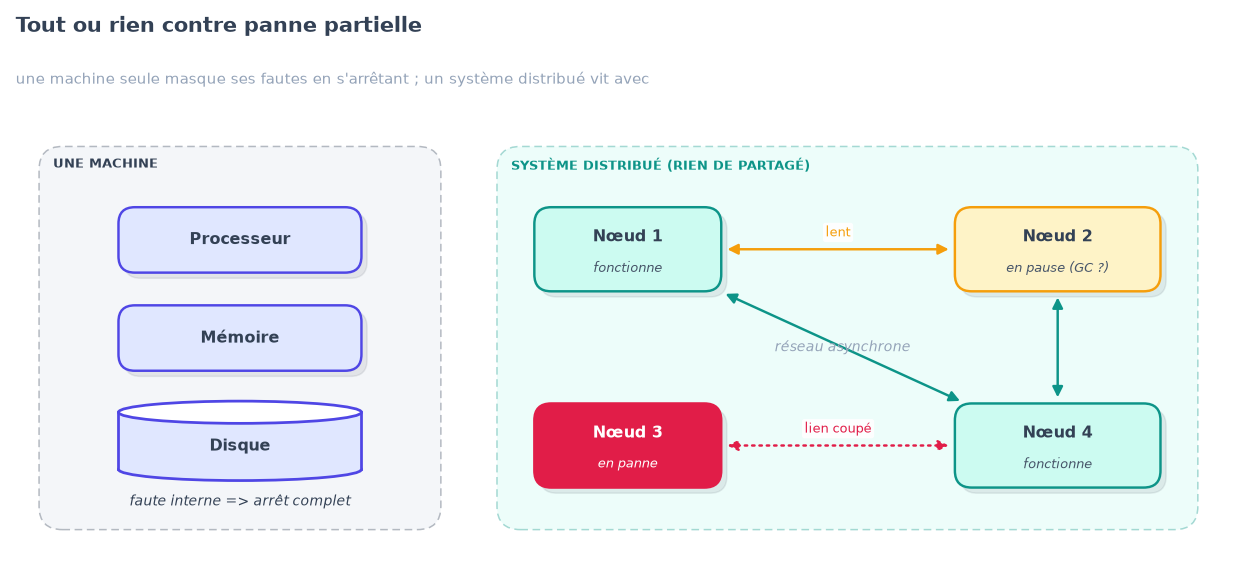

In [2]:
d = Diagram(13, 5.0, title="Tout ou rien contre panne partielle",
            subtitle="une machine seule masque ses fautes en s'arrêtant ; un système distribué vit avec")
d.group(0.3, 0.4, 4.6, 4.5, "une machine", color=SLATE)
d.box("cpu", 2.45, 3.5, "Processeur", color=INDIGO, w=2.6, h=0.7)
d.box("mem", 2.45, 2.45, "Mémoire", color=INDIGO, w=2.6, h=0.7)
d.box("dsk", 2.45, 1.35, "Disque", color=INDIGO, kind="db", w=2.6, h=0.85)
d.note(2.45, 0.7, "faute interne => arrêt complet", color=SLATE)
d.group(5.2, 0.4, 12.7, 4.5, "système distribué (rien de partagé)", color=TEAL)
d.box("n1", 6.6, 3.4, "Nœud 1", sub="fonctionne", color=TEAL, w=2.0)
d.box("n2", 11.2, 3.4, "Nœud 2", sub="en pause (GC ?)", color=AMBER, w=2.2)
d.box("n3", 6.6, 1.3, "Nœud 3", sub="en panne", color=ROSE, w=2.0, filled=True)
d.box("n4", 11.2, 1.3, "Nœud 4", sub="fonctionne", color=TEAL, w=2.2)
d.arrow("n1", "n2", "lent", color=AMBER, both=True)
d.arrow("n1", "n4", "", color=TEAL, both=True)
d.arrow("n3", "n4", "lien coupé", color=ROSE, style="dotted", both=True)
d.arrow("n2", "n4", "", color=TEAL, both=True)
d.note(8.9, 2.35, "réseau asynchrone", color=GRAY)
d.show()

**Un sur un million, c'est tous les jours.** Si une requête doit toucher $n$ nœuds et que
chacun est en faute (transitoire ou durable) avec une probabilité $p$, la probabilité de
rencontrer au moins une faute vaut $1-(1-p)^n \approx np$ pour $np$ petit. À l'échelle d'un
service qui traite des milliards de requêtes par jour, l'événement « improbable » devient
une routine.

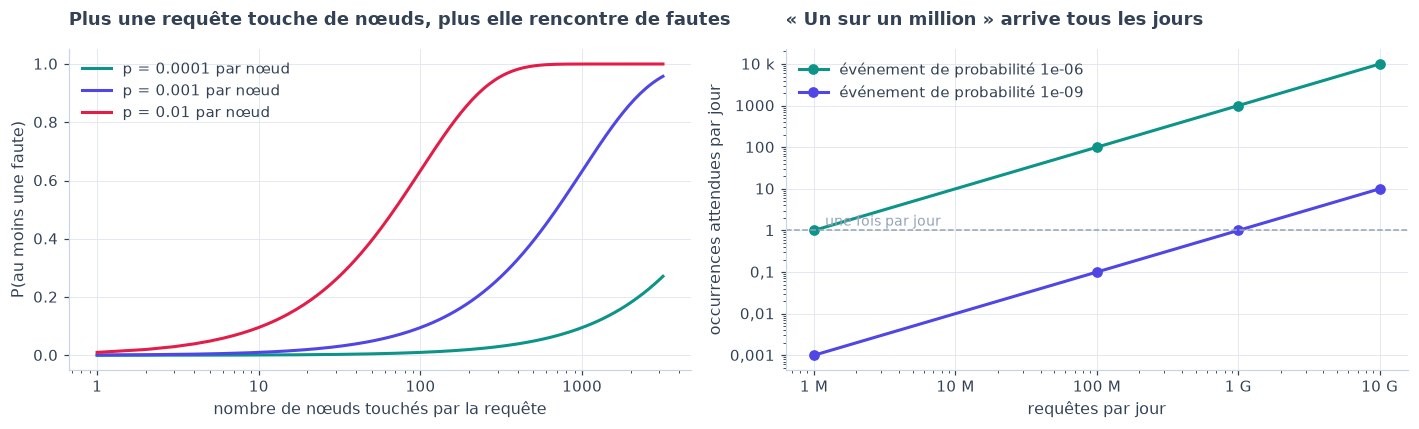

In [3]:
n = np.unique(np.logspace(0, 3.5, 200).astype(int))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ax = axes[0]
for p, c in [(1e-4, TEAL), (1e-3, INDIGO), (1e-2, ROSE)]:
    ax.plot(n, [ds.partial_failure_probability(p, k) for k in n], color=c, label=f"p = {p:g} par nœud")
ax.set_xscale("log"); plain_log_axis(ax, "x")
ax.set_xlabel("nombre de nœuds touchés par la requête")
ax.set_ylabel("P(au moins une faute)")
ax.set_title("Plus une requête touche de nœuds, plus elle rencontre de fautes")
ax.legend()
ax = axes[1]
volumes = np.array([1e6, 1e8, 1e9, 1e10])
for p, c in [(1e-6, TEAL), (1e-9, INDIGO)]:
    ax.plot(volumes, volumes * p, "o-", color=c, label=f"événement de probabilité {p:g}")
ax.axhline(1, color=GRAY, ls="--", lw=1)
ax.text(1.2e6, 1.3, "une fois par jour", color=GRAY, fontsize=9)
ax.set_xscale("log"); ax.set_yscale("log"); plain_log_axis(ax)
ax.set_xlabel("requêtes par jour"); ax.set_ylabel("occurrences attendues par jour")
ax.set_title("« Un sur un million » arrive tous les jours")
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

**Le non-déterminisme, mesuré.** Simulons sur `ddia.sim` une opération simple : un
client envoie une requête à un serveur et attend la réponse au plus 4 unités de temps.
Le réseau perd 5 % des messages et a des délais variables ; le serveur met un temps
variable à traiter (et fait parfois une longue pause). Répétons l'expérience avec 2 000
graines : du point de vue du client, il n'y a que deux issues (réponse ou délai
dépassé), mais du point de vue du serveur, la requête a pu être exécutée ou non.

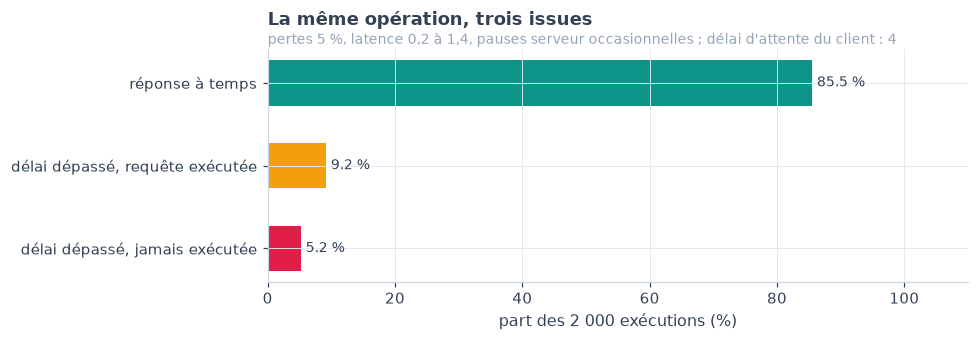

réponse à temps                    1711
délai dépassé, requête exécutée     184
délai dépassé, jamais exécutée      105
Name: count, dtype: int64

In [4]:
class Serveur(Node):
    def __init__(self, name, rng):
        super().__init__(name)
        self.rng, self.executed = rng, 0

    def on_message(self, src, msg):
        lent = self.rng.random() < 0.05                     # pause occasionnelle
        delay = self.rng.uniform(0.1, 0.5) + (self.rng.uniform(3, 8) if lent else 0)
        self.set_timer(delay, self._reply, src)

    def _reply(self, src):
        self.executed += 1
        self.send(src, "réponse")


class Client(Node):
    def __init__(self, name, timeout=4.0):
        super().__init__(name)
        self.timeout, self.answered_at = timeout, None

    def on_start(self):
        self.send("serveur", "requête")

    def on_message(self, src, msg):
        if self.answered_at is None:
            self.answered_at = self.now


def une_requete(seed):
    net = Network(seed=seed, latency=(0.2, 1.4), drop=0.05)
    import random as _r
    s = net.add(Serveur("serveur", _r.Random(seed + 10_000)))
    c = net.add(Client("client"))
    net.run(until=30)
    a_temps = c.answered_at is not None and c.answered_at <= c.timeout
    if a_temps:
        return "réponse à temps"
    return "délai dépassé, requête exécutée" if s.executed else "délai dépassé, jamais exécutée"


issues = pd.Series([une_requete(s) for s in range(2000)]).value_counts()
fig, ax = plt.subplots(figsize=(9, 3.2))
order = ["réponse à temps", "délai dépassé, requête exécutée", "délai dépassé, jamais exécutée"]
vals = issues.reindex(order).fillna(0) / issues.sum() * 100
ax.barh(order[::-1], vals.values[::-1], color=[ROSE, AMBER, TEAL], height=0.55)
annotate_bars(ax, "{:.1f} %")
ax.set_xlim(0, 110); ax.set_xlabel("part des 2 000 exécutions (%)")
ax.set_title("La même opération, trois issues")
subtitle(ax, "pertes 5 %, latence 0,2 à 1,4, pauses serveur occasionnelles ; délai d'attente du client : 4")
plt.tight_layout(); plt.show()
issues